## TCAV: ImageNet

Load default ResNet50 trained on ImageNet and predict prototypes for several classes.

In [1]:
!pwd
import sys
sys.path.append('./xplique/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import glob, cv2, pickle, os, time
from sklearn.metrics import label_ranking_average_precision_score as lrap
from scipy.stats import ttest_ind
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import log_loss
from sklearn.metrics.pairwise import cosine_similarity
from tensorflow.keras.applications import ResNet50
from xplique.concepts import Cav, Tcav

2024-03-13 15:06:12.746172: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-03-13 15:06:13.193426: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1
Physical devices cannot be modified after being initialized


2024-03-13 15:06:13.808408: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 47125 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
IMAGES_PATH   = '../data/Unsplash/images/'
CONCEPTS_PATH = '../data/Unsplash/prototypes/'
img_height = img_width = 224

### Load Test Images

In [5]:
classes = [c.split('/')[-1] for c in sorted(glob.glob(IMAGES_PATH + '*'))]
classes

['cheetah', 'snake', 'tiger', 'turtle', 'zebra']

In [6]:
test_set = tf.keras.utils.image_dataset_from_directory(
    IMAGES_PATH,
    shuffle=False,
    seed=123,
    image_size=(img_height, img_width),
    batch_size=None)

Found 212 files belonging to 5 classes.


In [7]:
# Preprocess raw images (required by resnet initialized with imagenet weights)
test_set = test_set.map(lambda x, y: (tf.keras.applications.resnet50.preprocess_input(x), y))

In [8]:
# Get concept label vector from tf.Dataset
y_true_img = np.asarray([lab.numpy() for _, lab in test_set])

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


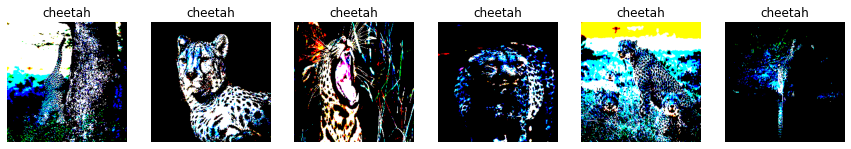

In [9]:
# Plot a few examples
plt.figure(figsize = (15, 10))
num_cols = 6
with tf.device('/CPU:0'):
    i=0
    for img, lab in test_set.take(num_cols):
        plt.subplot(1, num_cols, i + 1)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i+=1
plt.show()

### Load random images from broden

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i

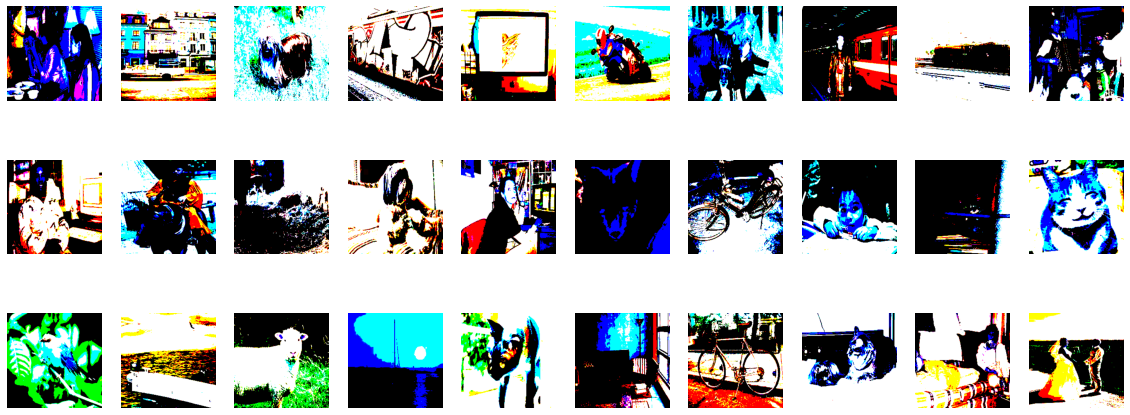

In [10]:
random_img_folder = '../data/broden1_224/images/pascal/'
input_size = img_height

random_imgs = os.listdir(random_img_folder)
random_imgs_filter = lambda f : all([rm not in f for rm in ['object', 'color', 'part']]) # only take 'natural' image

# Load same random images used for tcav fungi
with open('./beexplainable/metafiles/Fungi/raw/fungi_tcav_random.pickle', 'rb') as handle:
    files = pickle.load(handle)

random_dataset = [cv2.imread(random_img_folder+img)[...,::-1] for img in files]
random_dataset = [tf.image.resize(img, [img_width, img_height]) for img in random_dataset]
random_dataset = np.array([tf.keras.applications.resnet50.preprocess_input(img) for img in random_dataset])

plt.figure(figsize = (20, 8))
for i in range(30):
    plt.subplot(3, 10, i+1)
    plt.imshow(random_dataset[i])
    plt.axis('off')

### Load Prototype Images

In [11]:
concepts_folder = CONCEPTS_PATH

concepts_files = os.listdir(concepts_folder)
concepts_availables = np.unique([t for t in concepts_files])
print('The available concepts are : \n', '; '.join(concepts_availables))

def load_concepts(concepts):
    files = glob.glob(CONCEPTS_PATH + concepts + '/*.jpg')
    imgs  = [cv2.imread(img)[...,::-1] for img in files]
    imgs  = [tf.image.resize(img, [img_width, img_height]) for img in imgs]
    imgs = [tf.keras.applications.resnet50.preprocess_input(img) for img in imgs]

    return np.array(imgs)

The available concepts are : 
 cheetah_proto; snake_proto; tiger_proto; turtle_proto; zebra_proto


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).




Texture: cheetah_proto  - shape: (30, 224, 224, 3)


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


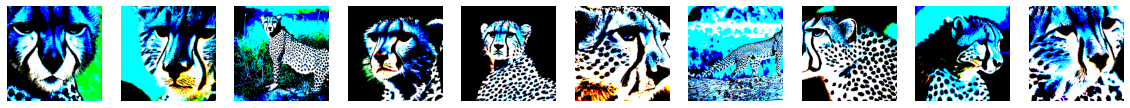

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: snake_proto  - shape: (30, 224, 224, 3)


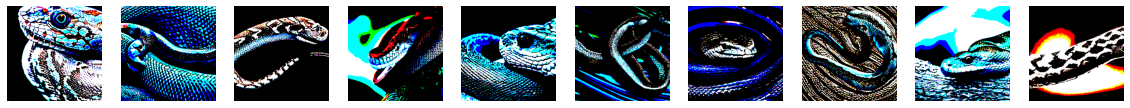

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: tiger_proto  - shape: (30, 224, 224, 3)


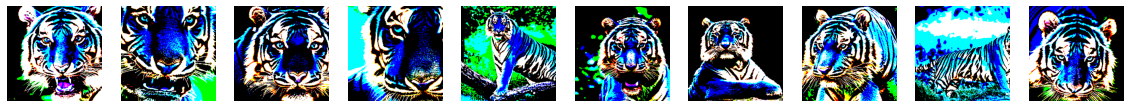

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: turtle_proto  - shape: (30, 224, 224, 3)


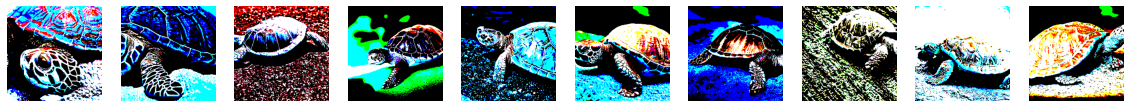

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i



Texture: zebra_proto  - shape: (30, 224, 224, 3)


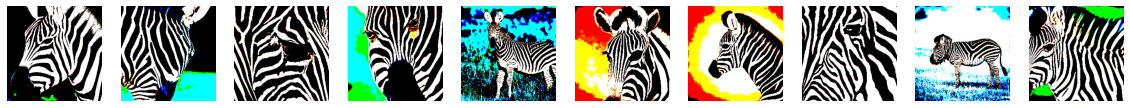

In [12]:
concepts = {concepts: load_concepts(concepts) for concepts in concepts_availables}

plt.rcParams["figure.figsize"] = [20, 8]
for concepts_name, images in concepts.items():
    print(f"\n\nTexture: {concepts_name}  - shape: {images.shape}")
    for i in range(10):
        plt.subplot(1, 10, i+1)
        plt.imshow(images[i])
        plt.axis('off')
    plt.show()

### Extract CAVs

In [13]:
# Load ResNet pretrained on ImageNet
model = ResNet50(input_shape=(img_height, img_width, 3), weights='imagenet', include_top=True)

In [14]:
# Define layer whose outputs will represent the latent space for the CAV
layer_target = 'avg_pool'

# Remove the softmax because we are only interested in the value of the logits
model.layers[-1].activation = tf.keras.activations.linear

In [15]:
cavs = {}
nb_repeat = 30
cav_extractor = Cav(model, layer_target, batch_size=64)
for concepts_name, imgs in concepts.items():

    for repeat_id in range(nb_repeat):
        # Choose different random images for each cav repetition
        random_ids = np.random.choice(len(random_dataset), len(imgs), replace = False)
        cav = cav_extractor(imgs, random_dataset[random_ids])

        if concepts_name not in cavs:
            cavs[concepts_name] = []

        cavs[concepts_name].append(cav)

    print(f"Done for concept {concepts_name}.")

2024-03-05 15:28:11.892853: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-03-05 15:28:12.375268: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-05 15:28:12.376348: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-05 15:28:12.376359: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-03-05 15:28:12.377368: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-03-05 15:28:12.377504: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.


Done for concept cheetah_proto.
Done for concept snake_proto.
Done for concept tiger_proto.
Done for concept turtle_proto.
Done for concept zebra_proto.


In [16]:
# Do the same things for random images
for repeat_id in range(nb_repeat):
    # Choose many random images, half as positive and half as negative
    random_ids = np.random.choice(len(random_dataset), 500, replace = False)
    random_1, random_2 = random_ids[:250], random_ids[250:]

    cav = cav_extractor(random_dataset[random_1], random_dataset[random_2])

    if 'random' not in cavs:
        cavs['random'] = []

    cavs['random'].append(cav)

print(f"Done for Random.")

Done for Random.


### Measure Cos-Sim and BCE of predicted concepts

In [13]:
# One-hot-encode the concepts
concept_basis = OneHotEncoder().fit_transform([[0], [1], [2], [3], [4]]).toarray()
lookup_cls_concepts = [concept_basis[0], # cheetah
                       concept_basis[1], # snake
                       concept_basis[2], # tiger
                       concept_basis[3], # turtle
                       concept_basis[4]] # zebra

In [18]:
probs_cls_dict, pvals_cls_dict = {}, {}
tcav_scores = {}
cav_tester = Tcav(model, layer_target)
start_time = time.time()
for explained_spec in range(len(classes)):

    ### Compute TCAV scores ###
    imgs_cav = test_set
    imgs_cav = imgs_cav.filter(lambda img_cav, lab: lab == explained_spec)
    imgs_cav = imgs_cav.map(lambda img_cav, lab: tf.numpy_function(np.array, [img_cav], tf.float32))
    imgs_cav = list(imgs_cav.as_numpy_iterator())
    imgs_cav = np.array(imgs_cav)

    cls_name = classes[explained_spec]
    tcav_scores[cls_name] = {}

    # For the chosen concept, we take all the CAVs and test them against that class
    for concept_name, _cavs in cavs.items():
        tcav_scores[cls_name][concept_name] = []
        for cav in _cavs:
            score = cav_tester(imgs_cav, explained_spec, cav)
            tcav_scores[cls_name][concept_name].append(score)

    concept_score = []
    for concept_id, concept_name in enumerate(tcav_scores[cls_name].keys()):
        scores = tcav_scores[cls_name][concept_name]
        mean = np.mean(scores)
        concept_score.append((concept_name, mean))

    means = [mean for concept_name, mean in concept_score]
    probs_cls_dict[classes[explained_spec]] = np.asarray(means)

    # The p-values will attest to the significance of a cav in relation to random cavs
    p_values = np.array([ttest_ind(tcav_scores[cls_name][concept_name],
                         tcav_scores[cls_name]['random'], equal_var = True)[1]
               for concept_name in tcav_scores[cls_name].keys()])
    pvals_cls_dict[classes[explained_spec]] = p_values

print("--- %s seconds ---" % (time.time() - start_time))

--- 28.74881887435913 seconds ---


In [19]:
probs_cls_dict

{'cheetah': array([0.3       , 0.8       , 0.63333333, 0.9       , 0.33333333,
        0.5       ]),
 'snake': array([0.5       , 0.86666667, 0.76666667, 0.96666667, 0.5       ,
        0.46666667]),
 'tiger': array([0.3       , 0.5       , 0.43333333, 0.66666667, 0.56666667,
        0.3       ]),
 'turtle': array([0.43333333, 0.4       , 0.23333333, 0.1       , 0.36666667,
        0.5       ]),
 'zebra': array([0.23333333, 0.46666667, 0.03333333, 0.6       , 0.23333333,
        0.66666667])}

In [20]:
pvals_cls_dict

{'cheetah': array([1.17723778e-01, 1.43974584e-02, 3.05435447e-01, 4.90197092e-04,
        1.96676769e-01, 1.00000000e+00]),
 'snake': array([8.00284974e-01, 7.29319595e-04, 1.64710498e-02, 4.22635416e-06,
        8.00284974e-01, 1.00000000e+00]),
 'tiger': array([1.        , 0.11772378, 0.29182054, 0.00393583, 0.03762975,
        1.        ]),
 'turtle': array([6.11993857e-01, 4.44831474e-01, 3.23477630e-02, 4.90197092e-04,
        3.05435447e-01, 1.00000000e+00]),
 'zebra': array([5.05393764e-04, 1.22050615e-01, 7.36803629e-09, 5.99473119e-01,
        5.05393764e-04, 1.00000000e+00])}

In [21]:
# Normalize proto. relevance scores for every class so that they add up maximally to 1
probs_arr = np.array(list(probs_cls_dict.values()))[:,:-1] # discard random prob.
probs_cls_norm = probs_arr / len(concepts)
probs_cls_norm

array([[0.06      , 0.16      , 0.12666667, 0.18      , 0.06666667],
       [0.1       , 0.17333333, 0.15333333, 0.19333333, 0.1       ],
       [0.06      , 0.1       , 0.08666667, 0.13333333, 0.11333333],
       [0.08666667, 0.08      , 0.04666667, 0.02      , 0.07333333],
       [0.04666667, 0.09333333, 0.00666667, 0.12      , 0.04666667]])

In [35]:
# Normalized probs
probs_con_dict = {}
con_list = list(concepts.keys())
for c in con_list:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_cls_norm[i][con_list.index(c)]
probs_con_dict

{'cheetah_proto': array([0.06      , 0.1       , 0.06      , 0.08666667, 0.04666667]),
 'snake_proto': array([0.16      , 0.17333333, 0.1       , 0.08      , 0.09333333]),
 'tiger_proto': array([0.12666667, 0.15333333, 0.08666667, 0.04666667, 0.00666667]),
 'turtle_proto': array([0.18      , 0.19333333, 0.13333333, 0.02      , 0.12      ]),
 'zebra_proto': array([0.06666667, 0.1       , 0.11333333, 0.07333333, 0.04666667])}

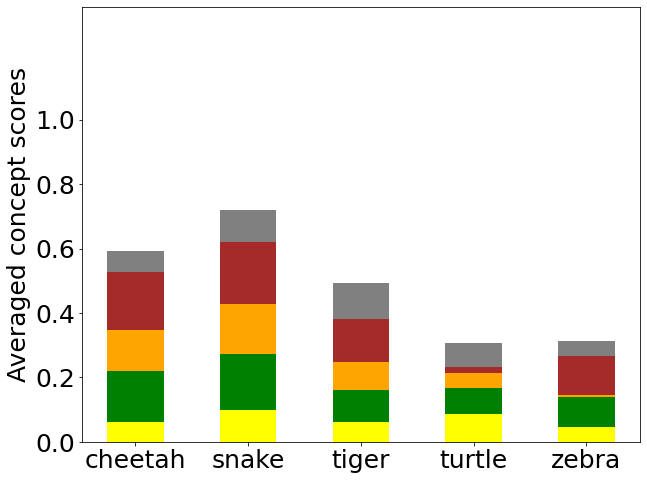

In [23]:
con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']
fontsize = 25
plt.figure(figsize=(10,8))
bottom = np.zeros(len(classes))
for i, (con, probs) in enumerate(probs_con_dict.items()):
    plt.bar(classes, probs, width=0.5, label=con, bottom=bottom, color=con_colors[i])
    bottom += probs

plt.ylim(0.0, 1.35)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.xticks(fontsize=fontsize); plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_tcav_stacked.png', bbox_inches='tight')
plt.show()

In [36]:
# Unnormalized probs
probs_con_dict = {}
con_list = list(concepts.keys())
for c in con_list:
    probs_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        probs_con_dict[c][i] = probs_arr[i][con_list.index(c)]
probs_con_dict

{'cheetah_proto': array([0.3       , 0.5       , 0.3       , 0.43333333, 0.23333333]),
 'snake_proto': array([0.8       , 0.86666667, 0.5       , 0.4       , 0.46666667]),
 'tiger_proto': array([0.63333333, 0.76666667, 0.43333333, 0.23333333, 0.03333333]),
 'turtle_proto': array([0.9       , 0.96666667, 0.66666667, 0.1       , 0.6       ]),
 'zebra_proto': array([0.33333333, 0.5       , 0.56666667, 0.36666667, 0.23333333])}

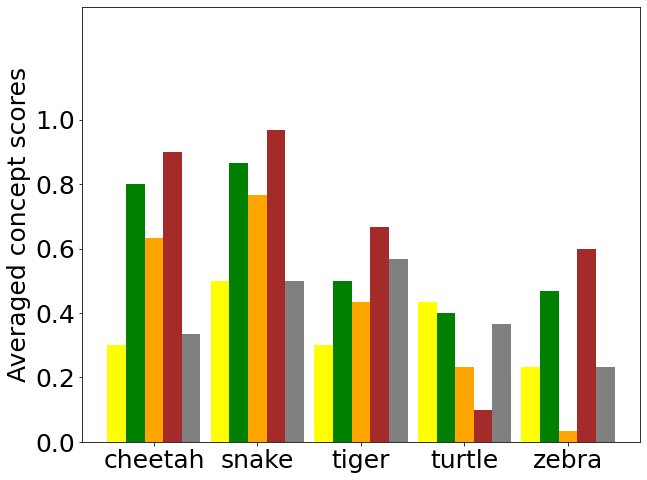

In [29]:
x = np.arange(len(classes))  # the label locations
width = 0.18  # the width of the bars
multiplier = -1
fontsize = 25
con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(probs_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height < 1e-3:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '$\diamond$', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Averaged concept scores', fontsize=fontsize)
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/mean_imagenet_tcav.png', bbox_inches='tight')
plt.show()

### Frequency of significant prototypes

In [27]:
count = 0
tcav_probs = [] # i-th row contains tcav scores for every concept for the i-th sample
cav_tester = Tcav(model, layer_target)
start_time = time.time()
for img_cav, explained_spec in test_set:

    ### Compute TCAV scores ###
    img_cav = tf.expand_dims(img_cav, axis=0)
    imgs_cav = tf.numpy_function(np.array, [img_cav], tf.float32)

    cls_name = classes[explained_spec]
    tcav_scores = {}

    # For the chosen concept, we take all the CAVs and test them against that class
    for concept_name, _cavs in cavs.items():
        tcav_scores[concept_name] = []
        for cav in _cavs:
            score = cav_tester(imgs_cav, explained_spec, cav)
            tcav_scores[concept_name].append(score)

    means = []
    for concept_id, concept_name in enumerate(tcav_scores.keys()):
        scores = tcav_scores[concept_name]
        mean = np.mean(scores)
        means.append(mean)
    tcav_probs.append( means )

    if count % 50 == 0: print(count)
    count += 1
print("--- %s seconds ---" % (time.time() - start_time))
tcav_probs = np.asarray(tcav_probs)

0
50
100
150
200
--- 481.6281704902649 seconds ---


In [14]:
metafolder = './beexplainable/metafiles/ImageNet/'
#with open(metafolder + 'tcav_probs.pkl', 'wb') as f:
#    pickle.dump(tcav_probs, f)
with open(metafolder + 'tcav_probs.pkl', 'rb') as f:
    tcav_probs = pickle.load(f)

In [15]:
for c in classes:
    tcav_probs_cls = tcav_probs[np.where(y_true_img == classes.index(c)), :-1][0] # leave out random component

    # Get true concept(s) based on true class
    true_con = lookup_cls_concepts[classes.index(c)]

    bce, cos_sim = [], []
    for p in tcav_probs_cls:
        # Compute binary cross entropy
        bce.append( log_loss(true_con, p) )
        # Compute cosine sim.
        cos_sim.append( cosine_similarity(true_con.reshape(1, -1), p.reshape(1, -1))[0][0] )

    # Rank correlation
    rank = lrap(np.tile(true_con, (len(tcav_probs_cls),1)), tcav_probs_cls)

    print(c)
    print('BCE:')
    print(str(np.round(np.mean(bce),4)) + '+/-' + str(np.round(np.std(bce),4)))
    print('Cosine Similarity:')
    print(str(np.round(np.mean(cos_sim),4)) + '+/-' + str(np.round(np.std(cos_sim),4)))
    print('Rank Correlation:')
    print(rank)
    print()

cheetah
BCE:
1.3476+/-0.0
Cosine Similarity:
0.2306+/-0.0
Rank Correlation:
0.20000000000000004

snake
BCE:
1.1641+/-0.0
Cosine Similarity:
0.5101+/-0.0
Rank Correlation:
0.5

tiger
BCE:
0.7775+/-0.0
Cosine Similarity:
0.3953+/-0.0
Rank Correlation:
0.25

turtle
BCE:
0.7152+/-0.0
Cosine Similarity:
0.2203+/-0.0
Rank Correlation:
0.20000000000000004

zebra
BCE:
1.0204+/-0.0
Cosine Similarity:
0.0709+/-0.0
Rank Correlation:
0.19999999999999996



In [24]:
# Count how often each concept is predicted as dominant concept (tcav_prob == max_prob)
sig_cls_dict = {}
for c in classes:
    cls_ind = np.where(y_true_img == classes.index(c))
    sig_cls_dict[c] = np.count_nonzero(tcav_probs[cls_ind, :len(concepts)][0] ==
                                       np.tile(np.max(tcav_probs[cls_ind, :len(concepts)][0], axis=1),
                                               (len(concepts),1)).T,
                                                axis=0) / len(cls_ind[0])
sig_cls_dict

{'cheetah': array([0., 0., 0., 1., 0.]),
 'snake': array([0., 0., 0., 1., 0.]),
 'tiger': array([0., 1., 0., 1., 0.]),
 'turtle': array([1., 0., 0., 0., 0.]),
 'zebra': array([0., 1., 0., 0., 0.])}

In [25]:
# Invert dictionary (for plotting purposes)
sig_con_dict = {}
for c in con_list:
    sig_con_dict[c] = np.zeros(len(classes))
    for i in range(len(classes)):
        sig_con_dict[c][i] = sig_cls_dict[classes[i]][con_list.index(c)]
sig_con_dict

{'cheetah_proto': array([0., 0., 0., 1., 0.]),
 'snake_proto': array([0., 0., 1., 0., 1.]),
 'tiger_proto': array([0., 0., 0., 0., 0.]),
 'turtle_proto': array([1., 1., 1., 0., 0.]),
 'zebra_proto': array([0., 0., 0., 0., 0.])}

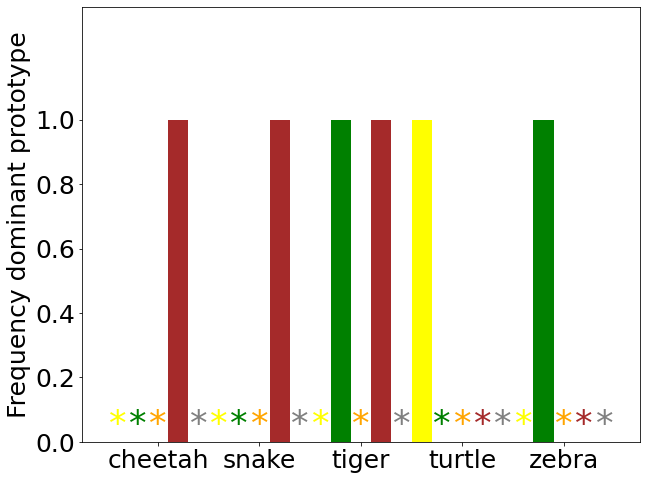

In [26]:
x = np.arange(len(classes))  # the label locations
width = 0.2  # the width of the bars
multiplier = -1
fontsize = 25
con_colors = con_colors = ['yellow', 'green', 'orange', 'brown', 'grey']

fig, ax = plt.subplots(figsize=(10, 8))  # Create axes for text placement
for i, (con, freq) in enumerate(sig_con_dict.items()):
   offset = width * multiplier
   rects = plt.bar(x + offset, freq, width, label=con, color=con_colors[i])
   multiplier += 1

   # Add asterisks for zero-height bars
   for rect, height in zip(rects, freq):
       if height == 0:
           ax.text(rect.get_x() + rect.get_width() / 2,
                   height,  # Adjust vertical position slightly
                   '*', ha='center', va='bottom', fontsize=fontsize+10, color=con_colors[i])

plt.xticks(x + width, classes, fontsize=fontsize)
plt.yticks(np.linspace(0.0, 1.0, 6), fontsize=fontsize)
plt.ylim(0.0, 1.35)
plt.ylabel('Frequency dominant prototype', fontsize=fontsize)
#plt.legend([c[:-4] for c in concepts], loc='upper right',
#           fontsize=fontsize, ncol=3, bbox_to_anchor=(1, 1))
plt.savefig('./beexplainable/figures/knn_vs_tcav_vs_ibd/imagenet_tcav_freq.png', bbox_inches='tight')
plt.show()